# A Hidden-State Failure

## When rerunning a perfectly ordinary cell silently changes the analysis

This demonstration notebook contains a very common interactive-programming mistake:

> **A transformation modifies a DataFrame in place, so rerunning the same cell applies the transformation twice.**

The notebook runs correctly from top to bottom after a fresh kernel restart.

But if an analyst reruns one ordinary-looking transformation cell during exploration, the results silently become wrong.

# Cell 1 — Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cell 2 — Load external data

In [2]:
rng = np.random.default_rng(556)

n = 120

df = pd.DataFrame({
    "site": rng.choice(
        ["North", "Central", "South"],
        size=n
    ),
    "sample_size": rng.integers(
        80,
        250,
        size=n
    ),
    # External source reports rates as percentages.
    "success_rate": np.clip(
        rng.normal(
            loc=82,
            scale=7,
            size=n
        ),
        55,
        99
    )
})

df.head()

,site,sample_size,success_rate
0,Central,197,73.724229
1,South,110,85.905640
2,North,105,79.218223
3,North,101,78.441037
4,South,110,86.298074


### Sanity check

At ingestion, `success_rate` is expressed as a **percentage**.

Values around 80 therefore mean approximately 80%, not 80 as a proportion.

In [3]:
df["success_rate"].describe()

count    120.000000
mean      81.542458
std        6.716937
min       62.121792
25%       77.056508
50%       81.908994
75%       87.168069
max       95.441912
Name: success_rate, dtype: float64

# Cell 3 — Convert percent to proportion

This is the problematic cell.

It looks completely ordinary:

In [4]:
#df["success_rate"] = (
    #df["success_rate"] / 100
#)

#df["success_rate"].head()

In [5]:
def convert_to_proportion(df, column):
    df_copy = df.copy()
    df_copy[column] = df[column] / 100
    return df_copy

prop_data = convert_to_proportion(df, "success_rate")
prop_data.head()

,site,sample_size,success_rate
0,Central,197,0.737242
1,South,110,0.859056
2,North,105,0.792182
3,North,101,0.784410
4,South,110,0.862981


# Cell 4 — Analysis

In [6]:
summary = (
    prop_data.groupby("site")
      .agg(
          n_sites=("success_rate", "size"),
          mean_success_rate=("success_rate", "mean"),
          sd_success_rate=("success_rate", "std")
      )
)

summary

,n_sites,mean_success_rate,sd_success_rate
site,,,
Central,34,0.808691,0.067281
North,46,0.830759,0.064797
South,40,0.803514,0.068038


# Cell 5 — Overall reported result

In [7]:
overall_mean = prop_data["success_rate"].mean()

print(
    f"Overall mean success rate: "
    f"{overall_mean:.3f}"
)

Overall mean success rate: 0.815


# Cell 6 — Figure

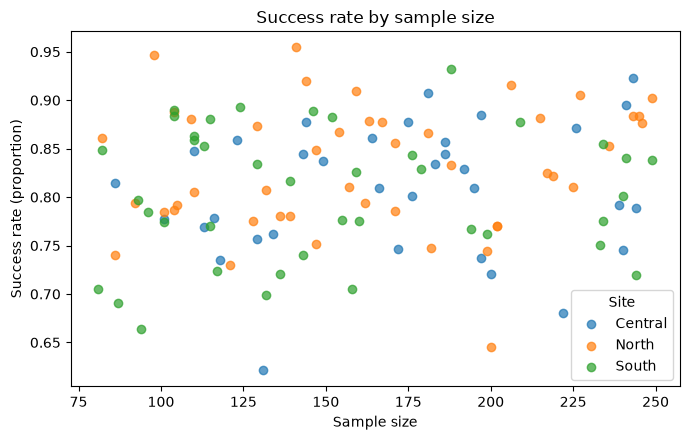

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for site, data in prop_data.groupby("site"):
    ax.scatter(
        data["sample_size"],
        data["success_rate"],
        label=site,
        alpha=0.7
    )

ax.set(
    title="Success rate by sample size",
    xlabel="Sample size",
    ylabel="Success rate (proportion)"
)

ax.legend(title="Site")
fig.tight_layout()

plt.show()